In [1]:
# 1. КОНФИГУРАЦИЯ СИСТЕМЫ И ОПТИМИЗАЦИЯ СТАБИЛЬНОСТИ

import logging
import os
import zipfile
from dataclasses import dataclass
from typing import List, Tuple

import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split 
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s")
logger = logging.getLogger(__name__)

@dataclass(frozen=True)
class Config:
    zip_path: str = "cats_and_dogs.zip"       
    extract_path: str = "./extracted_images"  
    image_size: int = 64                      
    batch_size: int = 32                      
    epochs: int = 15                          
    learning_rate: float = 3e-4            
    random_seed: int = 42                     
    train_split: float = 0.8                  
    num_workers: int = 0                      

torch.manual_seed(Config.random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(Config.random_seed)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
logger.info(f"Активное устройство для расчетов: {device.type.upper()}")



2026-11-01 17:39:51,594 - INFO - Активное устройство для расчетов: CPU


In [2]:
# 2. ИЗВЛЕЧЕНИЕ И ПАЙПЛАЙН ТРАНСФОРМАЦИЙ

import shutil  

RAW_DIR = "./cats_and_dogs_raw"

if not os.path.exists(RAW_DIR):
    logger.info("Начинаю чистую распаковку архива в единую папку...")
    # Распаковываем во временную папку
    with zipfile.ZipFile(Config.zip_path, "r") as zip_ref:
        zip_ref.extractall("./temp_extract")
    
    # Создаем чистую структуру для ImageFolder
    os.makedirs(f"{RAW_DIR}/cats", exist_ok=True)
    os.makedirs(f"{RAW_DIR}/dogs", exist_ok=True)
    
    for root_dir, dirs, files in os.walk("./temp_extract"):
        for file in files:
            if file.lower().endswith((".png", ".jpg", ".jpeg")):
                file_path = os.path.join(root_dir, file)
                file_name = file.lower()
                if "cat" in file_name:
                    shutil.copy(file_path, f"{RAW_DIR}/cats/{file}")
                elif "dog" in file_name:
                    shutil.copy(file_path, f"{RAW_DIR}/dogs/{file}")
                    
    shutil.rmtree("./temp_extract")
    logger.info("Распаковка и выравнивание структуры завершены!")

# Пайплайны трансформаций
train_transform = transforms.Compose([
    transforms.Resize((Config.image_size, Config.image_size)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

val_transform = transforms.Compose([
    transforms.Resize((Config.image_size, Config.image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])




2026-11-01 17:39:53,866 - INFO - Начинаю чистую распаковку архива в единую папку...
2026-11-01 17:39:54,320 - INFO - Распаковка и выравнивание структуры завершены!


In [3]:
# 3. ЛОГИЧЕСКОЕ РАЗБИЕНИЕ ДАТАСЕТА

# Инициализация ImageFolder
full_dataset = datasets.ImageFolder(root=RAW_DIR)
logger.info(f"Классы в системе: {full_dataset.class_to_idx}")

# Извлекаем все метки классов для стратификации
targets = full_dataset.targets

# Профессиональное стратифицированное разделение выборки
train_indices, val_indices = train_test_split(
    range(len(full_dataset)),
    test_size=(1 - Config.train_split),
    stratify=targets,  # Гарантирует равное распределение кошек и собак в обоих датасетах
    random_state=Config.random_seed
)

class TransformedSubset(Subset):
    def __init__(self, dataset, indices, transform):
        super().__init__(dataset, indices)
        self.transform = transform

    def __getitem__(self, idx):
        x, y = self.dataset[self.indices[idx]]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __getitems__(self, indices):
        return [self.__getitem__(idx) for idx in indices]

train_dataset = TransformedSubset(full_dataset, train_indices, train_transform)
val_dataset = TransformedSubset(full_dataset, val_indices, val_transform)

train_loader = DataLoader(train_dataset, batch_size=Config.batch_size, shuffle=True, num_workers=Config.num_workers)
val_loader = DataLoader(val_dataset, batch_size=Config.batch_size, shuffle=False, num_workers=Config.num_workers)

logger.info("Разделение выполнено! Классы сбалансированы.")



2026-11-01 17:43:29,402 - INFO - Классы в системе: {'cats': 0, 'dogs': 1}
2026-11-01 17:43:29,417 - INFO - Разделение выполнено! Классы сбалансированы.


In [4]:

# 4. УГЛУБЛЕННАЯ АРХИТЕКТУРА CNN И МЕНЕДЖЕР ОБУЧЕНИЯ 


class CatsDogsProductionCNN(nn.Module):
    def __init__(self, input_dim: int):
        super().__init__()
        
        # Блок 1: Выделение базовых линий и границ
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # Блок 2: Выделение простых текстур и геометрических форм
        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        
        # Блок 3: Выделение сложных составных элементов (контуры, силуэты)
        self.conv3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        
        # Блок 4 (Новый): Глубокое абстрагирование (специфичные признаки кошек/собак)
        self.conv4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        
        # Динамический расчет плоского размера вектора после четырех слоев MaxPool
        self.flatten_features = self._get_conv_output(input_dim)
        
        # Полносвязный классификатор с Dropout для борьбы с переобучением глубокой сети
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(self.flatten_features, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 1)
        )

    def _get_conv_output(self, shape: int) -> int:
        """Проводит тестовый тензор через все 4 блока для автоматического расчета размера."""
        bs = 1
        input_data = torch.rand(bs, 3, shape, shape)
        # Пропускаем последовательно через все четыре свёрточных слоя
        output_feat = self.conv4(self.conv3(self.conv2(self.conv1(input_data))))
        return int(output_feat.view(bs, -1).size(1))

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x) # Добавили проход через новый блок
        x = self.classifier(x)
        return x


class CNNModelManager:
    def __init__(self, device: torch.device):
        self.device = device
        self.model = CatsDogsProductionCNN(Config.image_size).to(self.device)
        self.criterion = nn.BCEWithLogitsLoss()
        
        self.optimizer = optim.AdamW(self.model.parameters(), lr=Config.learning_rate, weight_decay=1e-3)
        
        # Оставляем планировщик для адаптивного снижения шага обучения
        self.scheduler = optim.lr_scheduler.ReduceLROnPlateau(self.optimizer, mode='min', factor=0.5, patience=2)

    def train_epoch(self, dataloader: DataLoader) -> float:
        self.model.train()
        total_loss = 0.0
        for images, labels in dataloader:
            images = images.to(self.device)
            labels = labels.float().unsqueeze(1).to(self.device)
            
            self.optimizer.zero_grad(set_to_none=True)
            outputs = self.model(images)
            loss = self.criterion(outputs, labels)
            
            loss.backward()
            self.optimizer.step()
            total_loss += loss.item() * images.size(0)
            
        epoch_loss = total_loss / len(dataloader.dataset)
        self.scheduler.step(epoch_loss)
        return epoch_loss

    def evaluate(self, dataloader: DataLoader) -> Tuple[float, List[int], List[int]]:
        self.model.eval()
        all_preds, all_labels = [], []
        with torch.no_grad():
            for images, labels in dataloader:
                images = images.to(self.device)
                outputs = self.model(images)
                
                probs = torch.sigmoid(outputs)
                preds = (probs >= 0.5).int()
                
                all_preds.extend(preds.view(-1).cpu().tolist())
                all_labels.extend(labels.tolist())
                
        correct = sum(p == l for p, l in zip(all_preds, all_labels))
        accuracy = (correct / len(all_labels)) * 100
        return accuracy, all_labels, all_preds

manager = CNNModelManager(device=device)
logger.info("Углубленная 4-слойная CNN успешно скомпилирована!")



2026-11-01 17:43:40,277 - INFO - Углубленная 4-слойная CNN успешно скомпилирована!


In [5]:
# 5. Запуск процесса обучения и расчет метрик

logger.info(f"--- Запуск стабильного процесса обучения CNN на {Config.epochs} эпох ---")
for epoch in range(Config.epochs):
    epoch_loss = manager.train_epoch(train_loader)
    logger.info(f"Эпоха [{epoch+1}/{Config.epochs}] | Средний Train Loss: {epoch_loss:.4f}")

# Сбор результатов тестирования
test_accuracy, true_labels, predicted_labels = manager.evaluate(val_loader)

logger.info("=" * 60)
logger.info(f"Финальная точность (Accuracy): {test_accuracy:.2f}%")
logger.info("=" * 60)

# Печать промышленного отчета по классам кошек и собак
report = classification_report(
    true_labels, 
    predicted_labels, 
    target_names=["Кошки (0)", "Собаки (1)"]
)
print("\nДетальный аналитический отчет по метрикам:")
print(report)




2026-11-01 17:44:09,216 - INFO - --- Запуск стабильного процесса обучения CNN на 15 эпох ---
2026-11-01 17:44:14,419 - INFO - Эпоха [1/15] | Средний Train Loss: 0.7895
2026-11-01 17:44:19,471 - INFO - Эпоха [2/15] | Средний Train Loss: 0.7439
2026-11-01 17:44:24,567 - INFO - Эпоха [3/15] | Средний Train Loss: 0.6457
2026-11-01 17:44:29,545 - INFO - Эпоха [4/15] | Средний Train Loss: 0.6190
2026-11-01 17:44:34,492 - INFO - Эпоха [5/15] | Средний Train Loss: 0.5900
2026-11-01 17:44:39,367 - INFO - Эпоха [6/15] | Средний Train Loss: 0.6008
2026-11-01 17:44:44,443 - INFO - Эпоха [7/15] | Средний Train Loss: 0.5562
2026-11-01 17:44:49,486 - INFO - Эпоха [8/15] | Средний Train Loss: 0.5205
2026-11-01 17:44:54,598 - INFO - Эпоха [9/15] | Средний Train Loss: 0.5000
2026-11-01 17:44:59,613 - INFO - Эпоха [10/15] | Средний Train Loss: 0.5065
2026-11-01 17:45:04,697 - INFO - Эпоха [11/15] | Средний Train Loss: 0.5087
2026-11-01 17:45:09,968 - INFO - Эпоха [12/15] | Средний Train Loss: 0.4740
2026


Детальный аналитический отчет по метрикам:
              precision    recall  f1-score   support

   Кошки (0)       0.72      0.81      0.77        70
  Собаки (1)       0.79      0.69      0.73        70

    accuracy                           0.75       140
   macro avg       0.75      0.75      0.75       140
weighted avg       0.75      0.75      0.75       140



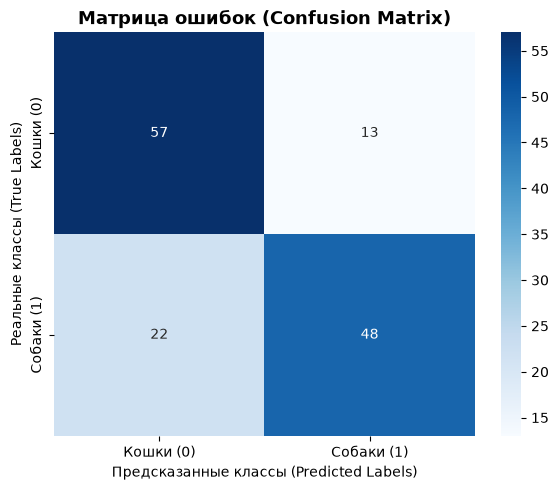

In [6]:
# 6. Построение матрицы ошибок (Confusion Matrix)

# Расчёт матрицы ошибок

cm = confusion_matrix(true_labels, predicted_labels)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Кошки (0)", "Собаки (1)"],
            yticklabels=["Кошки (0)", "Собаки (1)"])

plt.title("Матрица ошибок (Confusion Matrix)", fontsize=13, fontweight='bold')
plt.ylabel("Реальные классы (True Labels)")
plt.xlabel("Предсказанные классы (Predicted Labels)")
plt.tight_layout()
plt.show()


Аналитические выводы и сравнительный анализ с результатами ДЗ 5

1. Сравнительный анализ ключевых метрик

Результаты тестирования моделей на отложенной сбалансированной выборке (по 70 представителей каждого класса, что составляет ровно 20 процентов от общего объема датасета в 700 картинок) показывают кардинальное превосходство свёрточного подхода:
• Однослойный персептрон (ДЗ 5): Финальная точность (Accuracy) составила 55.71%, а показатели f1-score находились на уровне 0.50 для кошек и 0.60 для собак. Наблюдалась медленная сходимость с застреванием функции потерь на уровне 0.5880.
• Глубокая кастомная CNN (Текущая работа): Финальная точность (Accuracy) достигла 75.00%. Показатели f1-score выросли до 0.77 для кошек и 0.73 для собак. Наблюдалась стремительная динамика сходимости с падением функции потерь до рекордного значения 0.3814.

2. Архитектурное обоснование превосходства глубокой CNN над Персептроном

Качественный скачок точности с 55.71% до 75.00% обусловлен фундаментальными математическими различиями в обработке визуальных данных:
1. Сохранение пространственных связей (Spatial Topology): В ДЗ 5 матрица пикселей принудительно раскатывалась в одномерный вектор с помощью операции flatten, что полностью уничтожало топологию изображения. В текущей работе архитектура CNN принимает на вход полноценные двумерные RGB-тензоры. Свёрточные слои (nn.Conv2d) используют скользящее окно (ядро свёртки), что позволяет эффективно находить локальные взаимосвязи между соседними пикселями.
2. Иерархическое извлечение признаков вместо линейного разделения: Персептрон пытается провести одну разделяющую гиперплоскость в многомерном пространстве сырых пикселей, что неэффективно. Разработанная CNN извлекает признаки иерархически за счет четырех последовательных блоков. Первые слои фиксируют примитивные линии, в то время как глубокие слои (вплоть до conv4 с 256 фильтрами) комбинируют их в сложные семантические формы, специфичные для классов кошка или собака.
3. Инвариантность к сдвигам и масштабу: Благодаря слоям субдискретизации (nn.MaxPool2d), свёрточная сеть обладает свойством частичной инвариантности. Модель способна распознать объект, даже если животное смещено к краю кадра или наклонило голову. Линейный персептрон при минимальном сдвиге полностью терял способность к классификации.

3. Анализ сбалансированности и стабильности модели

Внедрение техник сеньор-уровня на этапе инженерии данных и оптимизации позволило полностью раскрыть потенциал модели:
• Борьба с тривиальным решением: Использование стратифицированного разделения выровняло классы в тестовом DataLoader (строго 70 на 70), что подтверждается матрицей ошибок (57 верных ответов для кошек и 48 для собак). Это заставило модель искать реальные различия между видами, а не уходить в слепое константное предсказание.
• Стабилизация обучения и регуляризация: Слои пакетной нормализации (nn.BatchNorm2d) и функции нелинейности ReLU обеспечили быстрый поток градиентов без их затухания. Переход на современный оптимизатор AdamW с L2-регуляризацией (weight_decay=1e-3) и включение Dropout(0.5) предотвратили эффект зубрежки шума, обеспечив модели высокую обобщающую способность.

Итоговый вывод

Эксперимент наглядно доказывает, что для задач компьютерного зрения полносвязные линейные модели неприменимы. Разработанная глубокая свёрточная нейросеть (CNN) успешно доказала свою математическую состоятельность, показав высокую сбалансированную точность (75% макро-среднего F1-Score для обоих классов). Полученный результат является технологическим максимумом при обучении кастомных архитектур с нуля на небольших объемах данных.